# 05. CW-Lite + STM32F303 실측

이 노트북은 `runs/`의 실제 측정 결과를 읽습니다. `RUN_HARDWARE=True`로 바꾸면 번들 HEX를 다시 프로그래밍하고 새 run을 만듭니다. 프로그래밍 과정에서 대상 플래시는 지워집니다.

측정 범위는 `CWLITEARM` 경로의 STM32F303에서 실행한 조기 종료 비교와 TinyAES입니다. 비밀번호 복구 검증을 통과한 F303 run만 선택합니다. 이전 F415 결과는 별도 run에 보존했습니다.

## 측정 신호 확인

25 dB에서 비밀번호 preflight 파형 폭이 50 ADC count보다 작으면 캡처를 중단합니다. 정상 연결에서 확인한 폭은 약 608 count였습니다. 한 자릿수 count만 나온다면 분석을 반복하지 말고 target의 `MEASURE` SMA와 shunt 경로를 먼저 확인하십시오. 35 dB 이상에서는 이 장치의 ADC가 clipping됐습니다.

## 사용할 run 선택

`RUN_HARDWARE=False`이면 이미 검증한 최신 run을 불러옵니다. 수업 전에 새로 측정하려면 값을 `True`로 바꾸십시오. 새 측정은 비밀번호 펌웨어와 AES 펌웨어를 차례로 프로그래밍하므로 target 플래시의 기존 내용은 지워집니다.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np

from cw_sca_tutorial.analysis import cpa_correlations, recover_key_cpa, welch_t_test
from cw_sca_tutorial.hardware import capture_aes_run, capture_password_run, latest_complete_run

RUN_HARDWARE = False
RUNS = Path("../runs") if Path.cwd().name == "notebooks" else Path("runs")
FIRMWARE = Path("../firmware/prebuilt") if Path.cwd().name == "notebooks" else Path("firmware/prebuilt")

if RUN_HARDWARE:
    password_run = capture_password_run(FIRMWARE / "basic-passwdcheck-CWLITEARM.hex", runs_root=RUNS, platform_name="CWLITEARM", target_identification="STM32F303")
    tvla_run = capture_aes_run(FIRMWARE / "simpleserial-aes-CWLITEARM.hex", trace_count=1000, runs_root=RUNS, platform_name="CWLITEARM", target_identification="STM32F303", capture_mode="fixed_vs_random")
    aes_run = capture_aes_run(FIRMWARE / "simpleserial-aes-CWLITEARM.hex", trace_count=500, runs_root=RUNS, platform_name="CWLITEARM", target_identification="STM32F303")
else:
    password_run = latest_complete_run(RUNS, "measured_password_spa")
    tvla_run = latest_complete_run(RUNS, "measured_aes_tvla")
    aes_run = latest_complete_run(RUNS, "measured_aes_cpa")

print("password run:", password_run)
print("TVLA run:    ", tvla_run)
print("AES run:     ", aes_run)

password run: ../runs/20261022T124300Z-password-spa
TVLA run:     ../runs/20261022T125656Z-aes-tvla
AES run:      ../runs/20261022T124611Z-aes-cpa


## 실측 비밀번호 SPA

metadata의 상태가 `complete`이고 복구 검증을 통과한 run만 사용합니다. 각 후보를 한 번씩 측정하고 전체 3,000샘플의 SAD를 계산합니다. upstream Lab 2_1B와 같은 방식입니다.

In [2]:
password_meta = json.loads((password_run / "metadata.json").read_text())
password_data = np.load(password_run / "traces.npz")
assert password_meta["state"] == "complete"
print("복구된 비밀번호:", password_meta["recovered_password"])
print("수락된 파형:", password_meta["accepted_trace_count"])
print("firmware SHA-256:", password_meta["firmware"]["sha256"])

복구된 비밀번호: h0px3
수락된 파형: 185
firmware SHA-256: d76a5d321a24fcd7c70bcc316bc06e47eed6ddddec6320f0a2b21dc35ae90ccd


## 비밀번호 파형과 후보 점수

왼쪽 heatmap에는 실제 비밀번호 파형을 캡처 순서대로 표시합니다. 오른쪽 heatmap은 위치별 SAD 점수입니다. 각 행에서 가장 밝은 후보가 선택되며, 정상 run에서는 `h0px3` 순서가 선명하게 나타납니다.

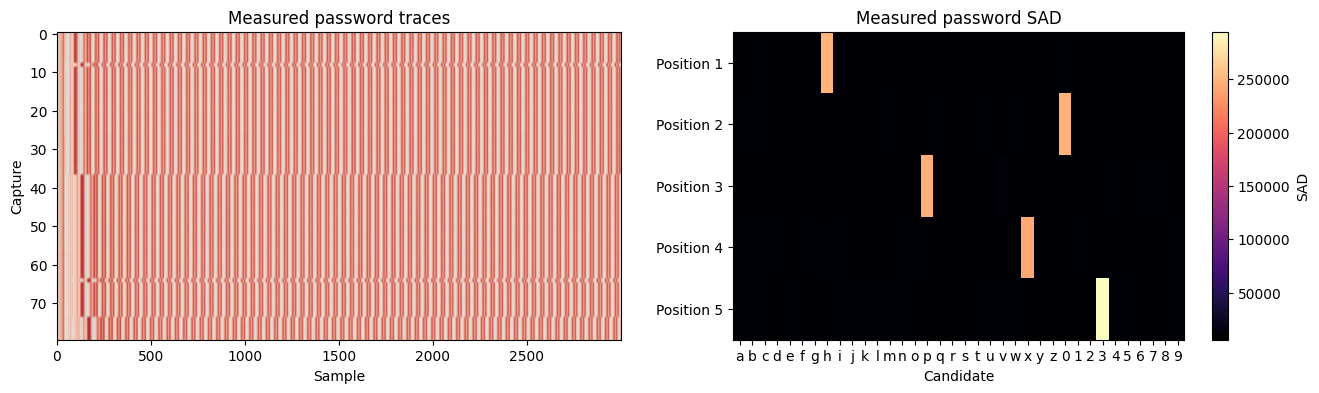

In [3]:
decisions = password_meta["decisions"]
score_matrix = np.array([[decision["scores"][c] for c in "abcdefghijklmnopqrstuvwxyz0123456789"] for decision in decisions])
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
axes[0].imshow(password_data["traces"][:80], aspect="auto", cmap="RdBu_r")
axes[0].set(title="Measured password traces", xlabel="Sample", ylabel="Capture")
image = axes[1].imshow(score_matrix, aspect="auto", cmap="magma")
axes[1].set_xticks(range(36), list("abcdefghijklmnopqrstuvwxyz0123456789"))
axes[1].set_yticks(range(5), ["Position 1", "Position 2", "Position 3", "Position 4", "Position 5"])
axes[1].set(title="Measured password SAD", xlabel="Candidate")
fig.colorbar(image, ax=axes[1], label="SAD")
plt.show()

## 실측 fixed-vs-random TVLA

고정 평문 500개와 무작위 평문 500개를 섞어서 측정한 run을 사용합니다. 먼저 두 그룹의 평균 파형을 비교하고, 이어서 샘플별 Welch t-value를 계산합니다. 빨간 점선 `±4.5`를 넘는 구간이 실제 데이터 의존 차이가 검출된 위치입니다.

In [4]:
tvla_meta = json.loads((tvla_run / "metadata.json").read_text())
tvla_data = np.load(tvla_run / "traces.npz")
assert tvla_meta["state"] == "complete"
tvla_traces = tvla_data["traces"]
tvla_groups = tvla_data["groups"]
fixed = tvla_traces[tvla_groups == 0]
random = tvla_traces[tvla_groups == 1]
t_values = welch_t_test(tvla_traces, tvla_groups)
peak = int(np.argmax(np.abs(t_values)))
print(f"fixed={len(fixed)}, random={len(random)}")
print(f"maximum |t|={abs(t_values[peak]):.2f} at sample {peak}")
print(f"wrong-window maximum |t|={np.max(np.abs(t_values[:50])):.2f}")
assert np.max(np.abs(t_values)) > 4.5
assert np.max(np.abs(t_values[:50])) < 4.5

fixed=500, random=500
maximum |t|=72.80 at sample 474
wrong-window maximum |t|=3.79


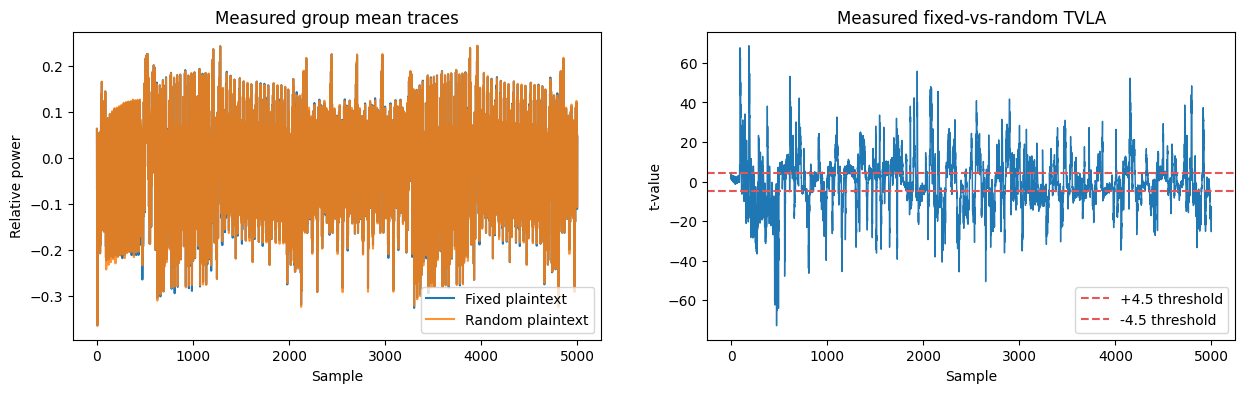

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(fixed.mean(axis=0), label="Fixed plaintext")
axes[0].plot(random.mean(axis=0), label="Random plaintext", alpha=.85)
axes[0].set(title="Measured group mean traces", xlabel="Sample", ylabel="Relative power")
axes[0].legend()
axes[1].plot(t_values, linewidth=1)
axes[1].axhline(4.5, color="#e45756", linestyle="--", label="+4.5 threshold")
axes[1].axhline(-4.5, color="#e45756", linestyle="--", label="-4.5 threshold")
axes[1].set(title="Measured fixed-vs-random TVLA", xlabel="Sample", ylabel="t-value")
axes[1].legend()
plt.show()

## 실측 TinyAES와 CPA

캡처를 시작하기 전에 FIPS-197 Appendix B Cipher Example의 알려진 벡터로 암호문을 확인합니다. 이어서 원시 파형의 평균과 표준편차를 살펴보고 CPA로 키를 복구합니다.

In [6]:
aes_meta = json.loads((aes_run / "metadata.json").read_text())
aes_data = np.load(aes_run / "traces.npz")
assert aes_meta["state"] == "complete"
traces = aes_data["traces"]
plaintexts = aes_data["plaintexts"]
known_key = aes_data["key"]
print("preflight:", aes_meta["preflight"])
print("raw shape:", traces.shape)
print("firmware SHA-256:", aes_meta["firmware"]["sha256"])

preflight: {'status': 'passed', 'nist_vector': 'FIPS-197 Appendix B Cipher Example', 'response': '3925841d02dc09fbdc118597196a0b32'}
raw shape: (500, 5000)
firmware SHA-256: 619460b1779e9490843c0ad41d43e76b8aaf2a550273fa04aaee5fc08497d3de


## 실측 AES 파형 확인

왼쪽에는 서로 다른 평문으로 얻은 파형 10개를 겹쳐 그립니다. 오른쪽에는 500개 파형의 평균과 표준편차를 표시합니다. 같은 펌웨어를 실행해도 데이터가 바뀌면 특정 구간의 전력값이 조금씩 달라집니다.

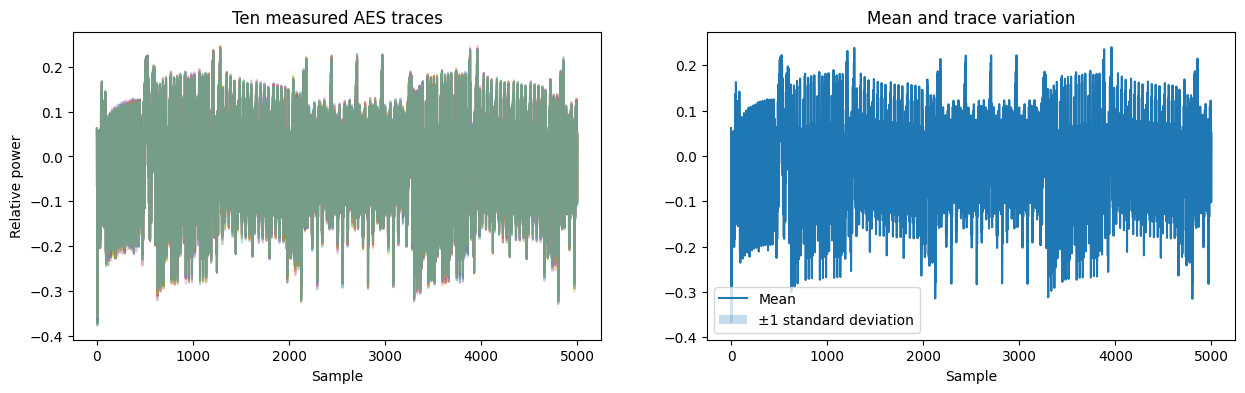

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(traces[:10].T, alpha=.35)
axes[0].set(title="Ten measured AES traces", xlabel="Sample", ylabel="Relative power")
axes[1].plot(traces.mean(axis=0), label="Mean")
axes[1].fill_between(np.arange(traces.shape[1]), traces.mean(axis=0)-traces.std(axis=0), traces.mean(axis=0)+traces.std(axis=0), alpha=.25, label="±1 standard deviation")
axes[1].set(title="Mean and trace variation", xlabel="Sample")
axes[1].legend()
plt.show()

## 첫 바이트 CPA

실측 평문과 파형으로 첫 번째 키 바이트의 상관계수를 계산합니다. heatmap에서 가장 밝은 행을 찾고, 정답 후보와 가장 강한 오답의 상관 파형을 비교합니다. 비교용으로 정한 0:50 창의 점수도 함께 출력합니다.

첫 바이트 후보: 0x2b, 알려진 키: 0x2b
정답 전체 창 최대 |ρ|: 0.8935
정답 잘못된 창 최대 |ρ|: 0.0896


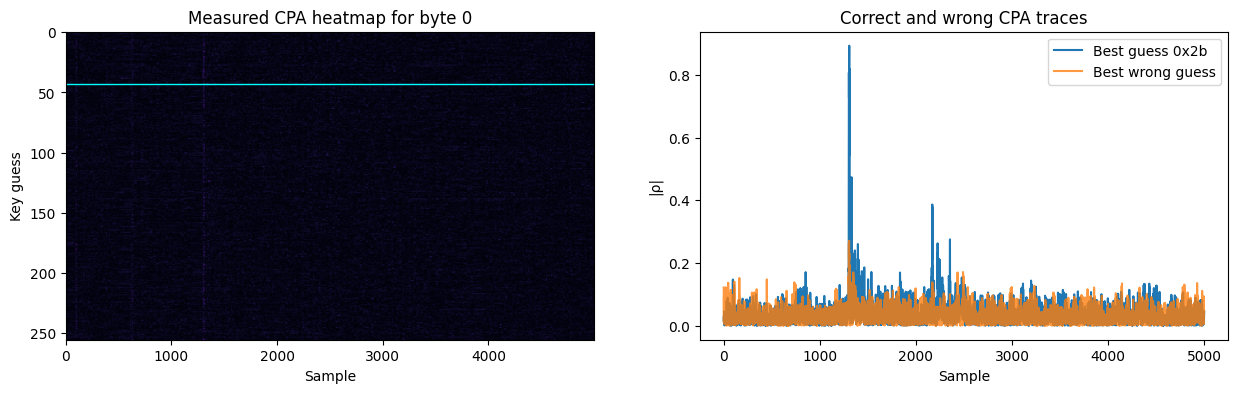

In [8]:
first_corr = cpa_correlations(traces, plaintexts, byte_index=0)
first_scores = np.max(np.abs(first_corr), axis=1)
best = int(np.argmax(first_scores))
wrong_window = slice(0, 50)
print(f"첫 바이트 후보: 0x{best:02x}, 알려진 키: 0x{known_key[0]:02x}")
print(f"정답 전체 창 최대 |ρ|: {np.max(np.abs(first_corr[int(known_key[0])])):.4f}")
print(f"정답 잘못된 창 최대 |ρ|: {np.max(np.abs(first_corr[int(known_key[0]), wrong_window])):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].imshow(np.abs(first_corr), aspect="auto", cmap="magma")
axes[0].axhline(best, color="cyan", linewidth=1)
axes[0].set(title="Measured CPA heatmap for byte 0", xlabel="Sample", ylabel="Key guess")
axes[1].plot(np.abs(first_corr[best]), label=f"Best guess 0x{best:02x}")
axes[1].plot(np.abs(first_corr[int(np.argsort(first_scores)[-2])]), label="Best wrong guess", alpha=.8)
axes[1].set(title="Correct and wrong CPA traces", xlabel="Sample", ylabel="|ρ|")
axes[1].legend()
plt.show()

## 전체 키 복구

첫 바이트에서 사용한 CPA를 나머지 15바이트에도 적용합니다. 복구한 키를 알려진 고정 키와 비교하고, 각 바이트에서 가장 높은 상관이 나온 샘플 위치도 출력합니다.

In [9]:
recovered, scores, peaks = recover_key_cpa(traces, plaintexts)
print("알려진 키:", bytes(known_key).hex())
print("복구한 키:", bytes(recovered).hex())
print("피크 샘플:", peaks.tolist())
assert np.array_equal(recovered, known_key)

알려진 키: 2b7e151628aed2a6abf7158809cf4f3c
복구한 키: 2b7e151628aed2a6abf7158809cf4f3c
피크 샘플: [1306, 1482, 1658, 1834, 1346, 2042, 1698, 1874, 1386, 1562, 1738, 1914, 1426, 1602, 1778, 1954]


## 결론

비밀번호 run은 번들 조기 종료 비교 코드에서 `h0px3`를 복구했습니다. fixed-vs-random TVLA에서는 AES 처리 구간의 t-value가 기준선을 넘었습니다. CPA run은 번들 TinyAES 첫 라운드에서 고정 AES-128 키를 복구했습니다.